In [1]:
import pathlib
import numpy as np
import scipy as sp
import pandas as pd 
from matplotlib import pyplot as plt


import statsmodels.api as sm
from statsmodels.formula.api import mixedlm, ols
import statsmodels.formula.api as smf

from statsmodels.stats.multitest import multipletests
import pingouin as pg

import SessionTools.two_photon as st2p
import el_hd_plasticity.two_photon as nmp

plt.rcParams['pdf.fonttype']=42

%load_ext autoreload
%autoreload 2 

%matplotlib inline

In [8]:
basedir = pathlib.Path('/media/mplitt/SSD_storage/2P_scratch/R60D05LexA_jGCaMP7b_R18B05Gal4_TBHRNAi')
sess_df = pd.read_csv(basedir / 'sessions.csv')
print(sess_df.columns)
sess_df['fly_id'] = [row['date']+'_'+row['fly'] +'_' + row['gal4_line'] + '_' + row['rnai_line '] for _, row in sess_df.iterrows()]

figfolder = pathlib.Path('/media/mplitt/SSD_storage/fig_scratch/R60D05LexA_jGCaMP7b_R18B05Gal4_TBHRNAi/')
figfolder.mkdir(parents=True, exist_ok=True)

sess_df = sess_df.loc[sess_df['usable']==1]
sess_df = sess_df.loc[~((sess_df['closed_loop']==0) * (sess_df['dark']==0))]

sess_df = sess_df.loc[sess_df['rnai_line '] != 'rnai_76062']

rnai = []
for _, row in sess_df.iterrows():
    if row['gal4_line']!='control':
        rnai.append(row['rnai_line '])
    else:
        rnai.append('gal4_control')
sess_df['rnai']=rnai


Index(['date', 'fly', 'sess', 'fictrac_scan_num', 'closed_loop', 'dark',
       'rnai_line ', 'gal4_line', 'usable', 'fictrac_dat_file', 'notes'],
      dtype='str')


In [9]:
sess_df.head()

,date,fly,sess,fictrac_scan_num,closed_loop,dark,rnai_line,gal4_line,usable,fictrac_dat_file,notes,fly_id,rnai
0,29_03_2024,fly2,closed_loop-000,0,1,0,rnai_67968,R18B05,1,fictrac-20240329_135950.dat,NaN,29_03_2024_fly2_R18B05_rnai_67968,rnai_67968
1,29_03_2024,fly2,dark-001,1,0,1,rnai_67968,R18B05,1,fictrac-20240329_135950.dat,NaN,29_03_2024_fly2_R18B05_rnai_67968,rnai_67968
2,29_03_2024,fly2,closed_loop-002,2,2,0,rnai_67968,R18B05,1,fictrac-20240329_135950.dat,NaN,29_03_2024_fly2_R18B05_rnai_67968,rnai_67968
3,29_03_2024,fly2,dark-003,3,0,1,rnai_67968,R18B05,1,fictrac-20240329_135950.dat,NaN,29_03_2024_fly2_R18B05_rnai_67968,rnai_67968
5,01_04_2024,fly1,closed_loop-000,0,1,0,rnai_67968,R18B05,1,fictrac-20240401_162130.dat,NaN,01_04_2024_fly1_R18B05_rnai_67968,rnai_67968


In [10]:
load_row = nmp.loading.make_load_row(basedir, folder_cols=('rnai',))
        
    

In [12]:

stats_df = nmp.tbh_rnai.offset_stats(sess_df, load_row)
stats_df_unique = nmp.tbh_rnai.offset_stats_unique(stats_df)
stats_df_plot = nmp.tbh_rnai.offset_stats_plot(stats_df_unique)

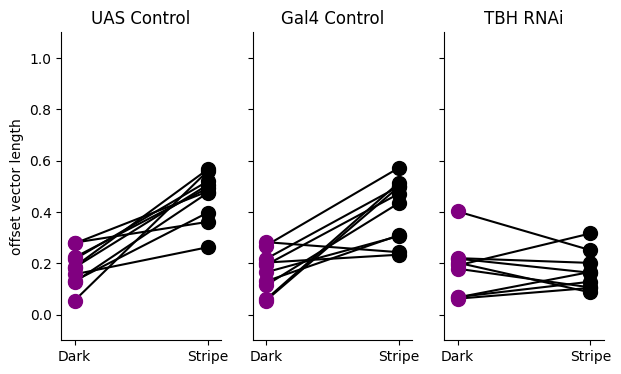

In [13]:
fig,ax = plt.subplots(1,3,sharey=True, figsize=[7,4])

c_df = stats_df_plot.loc[stats_df_plot['rnai']=='control']
ax[0].set_title('UAS Control')
# ax[0].plot([0,1], c_df[['offset_var_dark', 'offset_var_closed_loop']].T, color='black', zorder=-1)
# ax[0].scatter(np.zeros((c_df.shape[0],)), c_df['offset_var_dark'], color='purple', alpha=1, s=100)
# ax[0].scatter(np.ones((c_df.shape[0],)), c_df['offset_var_closed_loop'], color='black', alpha=1, s=100)
ax[0].plot([0,1], c_df[['offset_mag_dark', 'offset_mag_closed_loop']].T, color='black', zorder=-1)
ax[0].scatter(np.zeros((c_df.shape[0],)), c_df['offset_mag_dark'], color='purple', alpha=1, s=100)
ax[0].scatter(np.ones((c_df.shape[0],)), c_df['offset_mag_closed_loop'], color='black', alpha=1, s=100)

gal4_df = stats_df_plot.loc[stats_df_plot['rnai']=='gal4_control']
ax[1].set_title('Gal4 Control')
# ax[1].plot([0,1], gal4_df[['offset_var_dark', 'offset_var_closed_loop']].T, color='black', zorder=-1)
# ax[1].scatter(np.zeros((gal4_df.shape[0],)), gal4_df['offset_var_dark'], color='purple', alpha=1, s=100)
# ax[1].scatter(np.ones((gal4_df.shape[0],)), gal4_df['offset_var_closed_loop'], color='black', alpha=1, s=100)
ax[1].plot([0,1], gal4_df[['offset_mag_dark', 'offset_mag_closed_loop']].T, color='black', zorder=-1)
ax[1].scatter(np.zeros((gal4_df.shape[0],)), gal4_df['offset_mag_dark'], color='purple', alpha=1, s=100)
ax[1].scatter(np.ones((gal4_df.shape[0],)), gal4_df['offset_mag_closed_loop'], color='black', alpha=1, s=100)

tbh_df = stats_df_plot.loc[stats_df_plot['rnai']=='rnai_67968']
ax[2].set_title('TBH RNAi')
# ax[2].plot([0,1], tbh_df[['offset_var_dark', 'offset_var_closed_loop']].T, color='black', zorder=-1)
# ax[2].scatter(np.zeros((tbh_df.shape[0],)), tbh_df['offset_var_dark'], color='purple', alpha=1, s=100)
# ax[2].scatter(np.ones((tbh_df.shape[0],)), tbh_df['offset_var_closed_loop'], color='black', alpha=1, s=100)
ax[2].plot([0,1], tbh_df[['offset_mag_dark', 'offset_mag_closed_loop']].T, color='black', zorder=-1)
ax[2].scatter(np.zeros((tbh_df.shape[0],)), tbh_df['offset_mag_dark'], color='purple', alpha=1, s=100)
ax[2].scatter(np.ones((tbh_df.shape[0],)), tbh_df['offset_mag_closed_loop'], color='black', alpha=1, s=100)


for _ax in ax:
    _ax.set_ylim([-0.1,1.1])
    _ax.set_xlim([-.1,1.1])
    _ax.set_yticks([0,.2,.4,.6,.8,1.])

    _ax.set_xticks([0, 1], labels=['Dark', 'Stripe'])
    _ax.spines['top'].set_visible(False)
    _ax.spines['right'].set_visible(False)
    
ax[0].set_ylabel('offset vector length')


fig.savefig(figfolder / 'offset_mag_summary.pdf', format='pdf')

In [14]:
print(f"Gal 4 only control: N={c_df.shape[0]}")
print(f"RNAi only control: N={gal4_df.shape[0]}")
print(f"Exp: N={tbh_df.shape[0]}")

Gal 4 only control: N=10
RNAi only control: N=10
Exp: N=9


In [15]:
from pingouin import mixed_anova, pairwise_tests
aov = mixed_anova(dv='offset_var_logit', between='rnai',
                  within='dark', subject='fly_id', data=stats_df_unique.loc[stats_df_unique['rnai']!='rnai_76062'])
aov

,Source,SS,DF1,DF2,MS,F,p_unc,np2,eps
0,rnai,6.768731,2,26,3.384365,9.642038,0.000737,0.425847,NaN
1,dark,13.052490,1,26,13.052490,37.580948,0.000002,0.591072,1.0
2,Interaction,5.636634,2,26,2.818317,8.114546,0.001827,0.384311,NaN


In [16]:
tt = pairwise_tests(dv='offset_var_logit', between='rnai',
                   subject='fly_id', within='dark', data=stats_df_unique.loc[stats_df_unique['rnai']!='rnai_76062'],
                   padjust='holm', parametric=True, interaction=True, within_first=False)

print(tt['Contrast'].unique())
tt

['rnai' 'dark' 'rnai * dark']


,Contrast,rnai,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,hedges
0,rnai,-,control,gal4_control,False,True,-1.261845,18.000000,two-sided,0.223111,0.223111,holm,0.689,-0.540470
1,rnai,-,control,rnai_67968,False,True,-3.830162,12.179790,two-sided,0.002333,0.007000,holm,23.688,-1.731771
2,rnai,-,gal4_control,rnai_67968,False,True,-2.847357,13.258663,two-sided,0.013503,0.027007,holm,4.806,-1.280009
3,dark,-,0,1,True,True,-4.991798,28.000000,two-sided,0.000028,NaN,NaN,819.032,-1.267028
4,rnai * dark,control,0,1,True,True,-5.946566,9.000000,two-sided,0.000216,0.000649,holm,148.125,-2.771269
5,rnai * dark,gal4_control,0,1,True,True,-4.243838,9.000000,two-sided,0.002162,0.004324,holm,21.557,-2.082158
6,rnai * dark,rnai_67968,0,1,True,True,-0.086315,8.000000,two-sided,0.933337,0.933337,holm,0.323,-0.029782


In [17]:
tt = pairwise_tests(dv='offset_var', between='rnai',
                   subject='fly_id', within='dark', data=stats_df_unique.loc[stats_df_unique['rnai']!='rnai_76062'],
                   padjust='holm', parametric=True, interaction=True, within_first=True)

print(tt['Contrast'].unique())
print(tt['p-corr'])
tt

['dark' 'rnai' 'dark * rnai']


KeyError: 'p-corr'

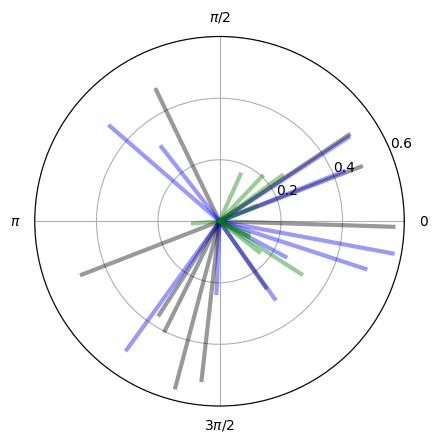

In [18]:


fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})

offsets = stats_df_unique.loc[(stats_df_unique['rnai']=='control') * (stats_df_unique['dark']==0),'offset_mean']#-np.pi
mag = stats_df_unique.loc[(stats_df_unique['rnai']=='control') * (stats_df_unique['dark']==0),'offset_mag']

for i, (o,m) in enumerate(zip(offsets.tolist(),mag.tolist())):
    # print(o,m)
    ax.plot([o,o],[0,m], linewidth=3, color='black',alpha=.4)
    
offsets = stats_df_unique.loc[(stats_df_unique['rnai']=='gal4_control') * (stats_df_unique['dark']==0),'offset_mean']#-np.pi
mag = stats_df_unique.loc[(stats_df_unique['rnai']=='gal4_control') * (stats_df_unique['dark']==0),'offset_mag']

for i, (o,m) in enumerate(zip(offsets.tolist(),mag.tolist())):
    # print(o,m)
    ax.plot([o,o],[0,m], linewidth=3, color='blue', alpha=.4)

offsets = stats_df_unique.loc[(stats_df_unique['rnai']=='rnai_67968') * (stats_df_unique['dark']==0),'offset_mean']#-np.pi
mag = stats_df_unique.loc[(stats_df_unique['rnai']=='rnai_67968') * (stats_df_unique['dark']==0),'offset_mag']

for i, (o,m) in enumerate(zip(offsets.tolist(),mag.tolist())):
    # print(o,m)
    ax.plot([o,o],[0,m], linewidth=3, color='green', alpha=.4)

    
_ = ax.set_rticks([.2, .4, .6])
_ = ax.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2], ['0', r'$\pi$/2', r'$\pi$', r'3$\pi$/2'])
    

fig.savefig(figfolder / 'offset_hist_summary.pdf', format='pdf')

### Compare bump amplitude vs speed for all flies

In [19]:
dh_bins = np.linspace(.0, 3.14/2, num=20)

stats_df = nmp.tbh_rnai.rho_stats(sess_df, load_row, dh_bins=dh_bins)

stats_df = stats_df.loc[stats_df['closed_loop']!=1] # exclude first closed loop session
stats_df.loc[stats_df['closed_loop']>1, 'closed_loop'] = 1 #
stats_df.loc[stats_df['dark']>=1, 'dark'] = 1 # 

grouped = stats_df.groupby(['fly_id','dark','rnai'])['rho_dig'].apply(lambda x: np.nanmean(np.stack(x),axis=0))
grouped = grouped.reset_index()

grouped.head()

,fly_id,dark,rnai,rho_dig
0,01_04_2024_fly1_R18B05_rnai_67968,0,rnai_67968,"[0.2631723645277917, 0.37987033217764565, 0.34..."
1,01_04_2024_fly1_R18B05_rnai_67968,1,rnai_67968,"[0.2939681909957137, 0.527351472292157, 0.5327..."
2,02_04_2024_fly2_R18B05_control,0,control,"[0.33635233532902387, 0.4260938452091892, 0.46..."
3,02_04_2024_fly2_R18B05_control,1,control,"[0.31804751233153855, 0.33647086302851914, 0.3..."
4,03_04_2024_fly1_R18B05_rnai_67968,0,rnai_67968,"[0.18974121594318233, 0.19835840709683744, 0.1..."


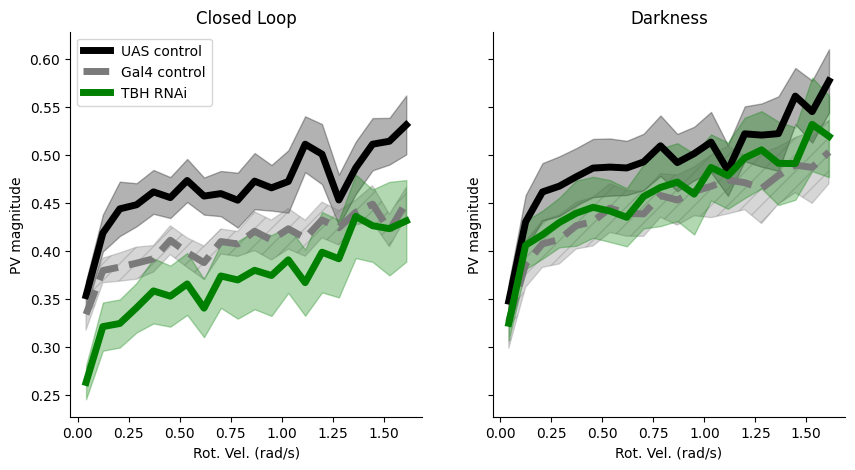

In [20]:
dh_bin_centers = dh_bins+np.diff(dh_bins)[0]/2
conditions = ('control','gal4_control', 'rnai_67968') 
rho_dict = {}
for cond in conditions:
    rho_dict[cond] = {'dark_rho':[],
                      'cl_rho':[]}

for fly in grouped['fly_id'].unique():
    if (grouped['fly_id']==fly).sum()>1:
        
        cond = grouped.loc[grouped['fly_id']==fly,'rnai'].iloc[0]
        
        dark_rho = grouped.loc[(grouped['fly_id']==fly) * (grouped['dark']==1), 'rho_dig']
        cl_rho = grouped.loc[(grouped['fly_id']==fly) * (grouped['dark']==0), 'rho_dig']
        
        
        rho_dict[cond]['dark_rho'].append(dark_rho.iloc[0])
        rho_dict[cond]['cl_rho'].append(cl_rho.iloc[0])

for cond in conditions:
    rho_dict[cond]['dark_rho'] = np.stack(rho_dict[cond]['dark_rho'])
    rho_dict[cond]['cl_rho'] = np.stack(rho_dict[cond]['cl_rho'])


fig, ax= plt.subplots(1,2, figsize=[10,5], sharey=True)
mu,sem = np.nanmean(rho_dict['control']['cl_rho'],axis=0), sp.stats.sem(rho_dict['control']['cl_rho'],axis=0,nan_policy='omit')
ax[0].plot(dh_bin_centers, mu, color='black', linewidth=5, label='UAS control')
ax[0].fill_between(dh_bin_centers, mu-sem, mu+sem, color='black', alpha=.3)


mu,sem = np.nanmean(rho_dict['gal4_control']['cl_rho'],axis=0), sp.stats.sem(rho_dict['gal4_control']['cl_rho'],axis=0,nan_policy='omit')
ax[0].plot(dh_bin_centers, mu, color=plt.cm.Greys(.6), linewidth=5, label ='Gal4 control', linestyle='--')
ax[0].fill_between(dh_bin_centers, mu-sem, mu+sem, color=plt.cm.Greys(.6), alpha=.3, hatch='//')


mu,sem = np.nanmean(rho_dict['rnai_67968']['cl_rho'],axis=0), sp.stats.sem(rho_dict['rnai_67968']['cl_rho'],axis=0,nan_policy='omit')
ax[0].plot(dh_bin_centers, mu, color='green', linewidth=5, label = 'TBH RNAi')
ax[0].fill_between(dh_bin_centers, mu-sem, mu+sem, color='green', alpha=.3)


ax[0].legend()


mu,sem = np.nanmean(rho_dict['control']['dark_rho'],axis=0), sp.stats.sem(rho_dict['control']['dark_rho'],axis=0,nan_policy='omit')
ax[1].plot(dh_bin_centers, mu, color='black', linewidth=5)
ax[1].fill_between(dh_bin_centers, mu-sem, mu+sem, color='black', alpha=.3)


mu,sem = np.nanmean(rho_dict['gal4_control']['dark_rho'],axis=0), sp.stats.sem(rho_dict['gal4_control']['dark_rho'],axis=0,nan_policy='omit')
ax[1].plot(dh_bin_centers, mu, color=plt.cm.Greys(.6), linewidth=5, label ='Gal4 control', linestyle='--')
ax[1].fill_between(dh_bin_centers, mu-sem, mu+sem, color=plt.cm.Greys(.6), alpha=.3, hatch='//')


mu,sem = np.nanmean(rho_dict['rnai_67968']['dark_rho'],axis=0), sp.stats.sem(rho_dict['rnai_67968']['cl_rho'],axis=0,nan_policy='omit')
ax[1].plot(dh_bin_centers, mu, color='green', linewidth=5)
ax[1].fill_between(dh_bin_centers, mu-sem, mu+sem, color='green', alpha=.3)



for a in ax:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.set_xlabel('Rot. Vel. (rad/s)')
    a.set_ylabel('PV magnitude')
ax[0].set_title('Closed Loop')
ax[1].set_title('Darkness')

fig.savefig(figfolder / 'PVMag_v_RotVel.pdf', format='pdf')
    

In [21]:
h,p = sp.stats.kruskal(np.nanmean(rho_dict['control']['cl_rho'],axis=-1), 
                       np.nanmean(rho_dict['gal4_control']['cl_rho'],axis=-1),
                            np.nanmean(rho_dict['rnai_67968']['cl_rho'], axis=-1))
print(h,p)

t,p = sp.stats.mannwhitneyu(np.nanmean(rho_dict['control']['cl_rho'],axis=-1), 
                            np.nanmean(rho_dict['rnai_67968']['cl_rho'], axis=-1))
print(t,p)

t,p = sp.stats.mannwhitneyu(np.nanmean(rho_dict['gal4_control']['cl_rho'],axis=-1), 
                            np.nanmean(rho_dict['rnai_67968']['cl_rho'], axis=-1))
print(t,p)


6.423029556650235 0.04029552822580376
64.0 0.03427944604415192
47.0 0.5726038667215138


In [22]:
h,p = sp.stats.kruskal(np.nanmean(rho_dict['control']['dark_rho'],axis=-1), 
                       np.nanmean(rho_dict['gal4_control']['dark_rho'],axis=-1),
                            np.nanmean(rho_dict['rnai_67968']['dark_rho'], axis=-1))
print(h,p)

t,p = sp.stats.mannwhitneyu(np.nanmean(rho_dict['control']['dark_rho'],axis=-1), 
                            np.nanmean(rho_dict['rnai_67968']['dark_rho'], axis=-1))
print(t,p)

t,p = sp.stats.mannwhitneyu(np.nanmean(rho_dict['gal4_control']['dark_rho'],axis=-1), 
                            np.nanmean(rho_dict['rnai_67968']['dark_rho'], axis=-1))
print(t,p)


1.4988916256157552 0.4726284047853536
47.0 0.5726038667215138
34.0 0.6334384569678687


In [23]:
# reformat for regression
reg_df = nmp.tbh_rnai.reformat_rho_stats_for_reg(grouped, dh_bins)
reg_df['log_rho'] = np.log(reg_df['rho']+1e-6)

<Axes: xlabel='Theoretical quantiles', ylabel='Ordered quantiles'>

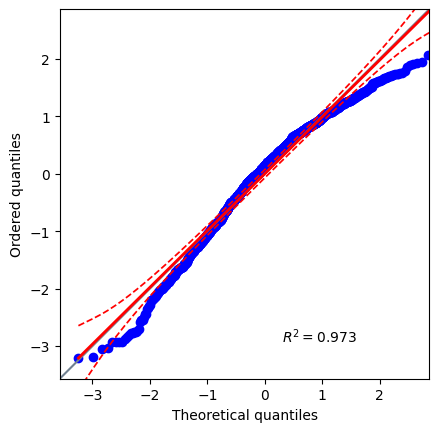

In [24]:
pg.qqplot(reg_df['log_rho'])

In [25]:
from pingouin import mixed_anova, pairwise_tests
aov = mixed_anova(dv='log_rho', between='rnai',
                  within='dh', subject='fly_id', data=reg_df.loc[reg_df['dark']==0])
aov

,Source,SS,DF1,DF2,MS,F,p_unc,p_GG_corr,np2,eps,sphericity,W_spher,p_spher
0,rnai,5.672898,2,25,2.836449,3.981503,3.154387e-02,NaN,0.241574,NaN,NaN,NaN,NaN
1,dh,3.874785,19,475,0.203936,31.466250,1.009778e-71,1.919584e-30,0.557258,0.407045,False,5.154815e-07,0.000004
2,Interaction,0.386311,38,475,0.010166,1.568574,1.887007e-02,NaN,0.111495,NaN,NaN,NaN,NaN


In [26]:
tt = pairwise_tests(dv='log_rho', between='rnai',
                   subject='fly_id', within='dh', data=reg_df.loc[reg_df['dark']==0],
                   padjust='holm', parametric=True, interaction=True, within_first=False)

# print(tt['Contrast'].unique())
tt
# tt.loc[tt['Contrast']=='dh * rnai']

,Contrast,rnai,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,hedges
0,rnai,-,control,gal4_control,False,True,1.980733,18.000000,two-sided,6.311253e-02,1.307826e-01,holm,1.462,0.848382
1,rnai,-,control,rnai_67968,False,True,2.282322,10.885485,two-sided,4.359420e-02,1.307826e-01,holm,2.122,1.090544
2,rnai,-,gal4_control,rnai_67968,False,True,1.224301,8.882494,two-sided,2.523169e-01,2.523169e-01,holm,0.685,0.601986
3,dh,-,0.0,0.082632,True,True,-8.609892,27.000000,two-sided,3.176090e-09,5.526397e-07,holm,3.805e+06,-0.794860
4,dh,-,0.0,0.165263,True,True,-7.585698,27.000000,two-sided,3.688716e-08,6.012607e-06,holm,3.818e+05,-0.840530
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
758,rnai * dh,rnai_67968,1.322105,1.487368,True,True,0.715909,7.000000,two-sided,4.972282e-01,1.000000e+00,holm,0.415,0.116291
759,rnai * dh,rnai_67968,1.322105,1.57,True,True,0.316943,7.000000,two-sided,7.605303e-01,1.000000e+00,holm,0.351,0.028082
760,rnai * dh,rnai_67968,1.404737,1.487368,True,True,0.380497,7.000000,two-sided,7.148595e-01,1.000000e+00,holm,0.357,0.070432
761,rnai * dh,rnai_67968,1.404737,1.57,True,True,-0.168188,7.000000,two-sided,8.711918e-01,1.000000e+00,holm,0.34,-0.023769


In [27]:
tt = pairwise_tests(dv='rho', between='rnai',
                   subject='fly_id', within='dh', data=reg_df.loc[reg_df['dark']==0],
                   padjust='holm', parametric=True, interaction=True, within_first=False)

tt

,Contrast,rnai,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,hedges
0,rnai,-,control,gal4_control,False,True,2.184551,18.000000,two-sided,4.239224e-02,1.006651e-01,holm,1.896,0.935681
1,rnai,-,control,rnai_67968,False,True,2.381831,12.735341,two-sided,3.355503e-02,1.006651e-01,holm,2.419,1.111969
2,rnai,-,gal4_control,rnai_67968,False,True,1.026050,9.644866,two-sided,3.299128e-01,3.299128e-01,holm,0.592,0.498696
3,dh,-,0.0,0.082632,True,True,-8.411636,27.000000,two-sided,5.050973e-09,8.889713e-07,holm,2.46e+06,-0.854534
4,dh,-,0.0,0.165263,True,True,-7.191442,27.000000,two-sided,9.827371e-08,1.601861e-05,holm,1.53e+05,-0.903402
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
758,rnai * dh,rnai_67968,1.322105,1.487368,True,True,0.528375,7.000000,two-sided,6.135708e-01,1.000000e+00,holm,0.378,0.092486
759,rnai * dh,rnai_67968,1.322105,1.57,True,True,0.356084,7.000000,two-sided,7.322677e-01,1.000000e+00,holm,0.355,0.036421
760,rnai * dh,rnai_67968,1.404737,1.487368,True,True,0.106479,7.000000,two-sided,9.181893e-01,1.000000e+00,holm,0.338,0.023330
761,rnai * dh,rnai_67968,1.404737,1.57,True,True,-0.247760,7.000000,two-sided,8.114304e-01,1.000000e+00,holm,0.345,-0.042008


In [28]:
tt = pairwise_tests(dv='rho', between='rnai',
                   subject='fly_id', within='dark', data=reg_df,
                   padjust='holm', parametric=True, interaction=True, within_first=False)

tt

,Contrast,rnai,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,hedges
0,rnai,-,control,gal4_control,False,True,1.769816,18.000000,two-sided,0.093695,0.281085,holm,1.14,0.758043
1,rnai,-,control,rnai_67968,False,True,1.491067,12.562694,two-sided,0.160621,0.321242,holm,0.865,0.697595
2,rnai,-,gal4_control,rnai_67968,False,True,0.290080,10.400331,two-sided,0.777456,0.777456,holm,0.426,0.139504
3,dark,-,0,1,True,True,-4.037382,27.000000,two-sided,0.000401,NaN,NaN,75.824,-0.543919
4,rnai * dark,control,0,1,True,True,-1.528559,9.000000,two-sided,0.160725,0.217777,holm,0.756,-0.320428
5,rnai * dark,gal4_control,0,1,True,True,-1.779346,9.000000,two-sided,0.108889,0.217777,holm,0.993,-0.537692
6,rnai * dark,rnai_67968,0,1,True,True,-4.501271,7.000000,two-sided,0.002794,0.008382,holm,17.975,-0.780379


Correlation of bump movement with turning in darkness vs closed loop


In [29]:
dh_bins = np.linspace(-2, 2, num=20)
stats_df = nmp.tbh_rnai.dphi_stats(sess_df, load_row, dh_bins)


stats_df = stats_df.loc[stats_df['closed_loop']!=1] # exclude first closed loop session
stats_df.loc[stats_df['closed_loop']>1, 'closed_loop'] = 1 #
stats_df.loc[stats_df['dark']>=1, 'dark'] = 1 # 

grouped = stats_df.groupby(['fly_id','dark','rnai'])['dphi_dig'].apply(lambda x: np.nanmean(np.stack(x),axis=0))

grouped = grouped.reset_index()
    


/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/two_photon/tbh_rnai.py:237: RuntimeWarning: Mean of empty slice
  dphi_dig = np.array([d_phi[dh_dig == i].mean() for i in range(len(dh_bins))])
/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/two_photon/tbh_rnai.py:237: RuntimeWarning: Mean of empty slice
  dphi_dig = np.array([d_phi[dh_dig == i].mean() for i in range(len(dh_bins))])
/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/two_photo

control
gal4_control
rnai_67968


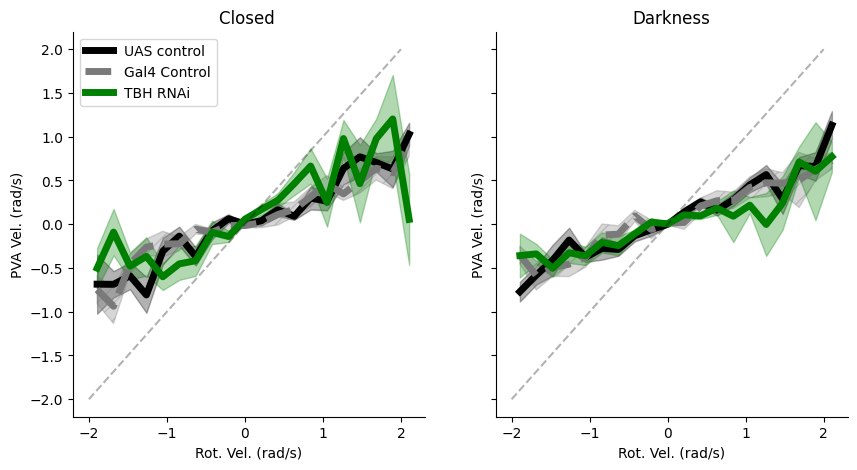

In [30]:
dh_bin_centers = dh_bins+np.diff(dh_bins)[0]/2
conditions = ('control','gal4_control', 'rnai_67968') 
dphi_dict = {}
for cond in conditions:
    dphi_dict[cond] = {'dark_dphi':[],
                      'cl_dphi':[]}

for fly in grouped['fly_id'].unique():
    if (grouped['fly_id']==fly).sum()>1:
        
        cond = grouped.loc[grouped['fly_id']==fly,'rnai'].iloc[0]
        
        dark_dphi = grouped.loc[(grouped['fly_id']==fly) * (grouped['dark']==1), 'dphi_dig']
        cl_dphi = grouped.loc[(grouped['fly_id']==fly) * (grouped['dark']==0), 'dphi_dig']
        
        dphi_dict[cond]['dark_dphi'].append(dark_dphi.iloc[0])
        dphi_dict[cond]['cl_dphi'].append(cl_dphi.iloc[0])
        
for cond in conditions:
    print(cond)
    dphi_dict[cond]['dark_dphi'] = np.stack(dphi_dict[cond]['dark_dphi'])
    dphi_dict[cond]['cl_dphi'] = np.stack(dphi_dict[cond]['cl_dphi'])


fig, ax= plt.subplots(1,2, figsize=[10,5], sharey=True)
mu,sem = np.nanmean(dphi_dict['control']['cl_dphi'],axis=0), sp.stats.sem(dphi_dict['control']['cl_dphi'],axis=0,nan_policy='omit')
ax[0].plot(dh_bin_centers, mu, color='black', linewidth=5, label='UAS control')
ax[0].fill_between(dh_bin_centers, mu-sem, mu+sem, color='black', alpha=.3)


mu,sem = np.nanmean(dphi_dict['gal4_control']['cl_dphi'],axis=0), sp.stats.sem(dphi_dict['gal4_control']['cl_dphi'],axis=0,nan_policy='omit')
ax[0].plot(dh_bin_centers, mu, color=plt.cm.Greys(.6), linewidth=5, label='Gal4 Control', linestyle='--')
ax[0].fill_between(dh_bin_centers, mu-sem, mu+sem, color=plt.cm.Greys(.6), alpha=.3, hatch='//')


mu,sem = np.nanmean(dphi_dict['rnai_67968']['cl_dphi'],axis=0), sp.stats.sem(dphi_dict['rnai_67968']['cl_dphi'],axis=0,nan_policy='omit')
ax[0].plot(dh_bin_centers, mu, color='green', linewidth=5, label='TBH RNAi')
ax[0].fill_between(dh_bin_centers, mu-sem, mu+sem, color='green', alpha=.3)

ax[0].legend()

mu,sem = np.nanmean(dphi_dict['control']['dark_dphi'],axis=0), sp.stats.sem(dphi_dict['control']['dark_dphi'],axis=0,nan_policy='omit')
ax[1].plot(dh_bin_centers, mu, color='black', linewidth=5)
ax[1].fill_between(dh_bin_centers, mu-sem, mu+sem, color='black', alpha=.3)


mu,sem = np.nanmean(dphi_dict['gal4_control']['dark_dphi'],axis=0), sp.stats.sem(dphi_dict['gal4_control']['dark_dphi'],axis=0,nan_policy='omit')
ax[1].plot(dh_bin_centers, mu, color=plt.cm.Greys(.6), linewidth=5, label='Gal4 Control', linestyle='--')
ax[1].fill_between(dh_bin_centers, mu-sem, mu+sem, color=plt.cm.Greys(.6), alpha=.3, hatch='//')



mu,sem = np.nanmean(dphi_dict['rnai_67968']['dark_dphi'],axis=0), sp.stats.sem(dphi_dict['rnai_67968']['dark_dphi'],axis=0,nan_policy='omit')
ax[1].plot(dh_bin_centers, mu, color='green', linewidth=5)
ax[1].fill_between(dh_bin_centers, mu-sem, mu+sem, color='green', alpha=.3)


for a in ax:
    
    a.plot([-2,2],[-2,2], 'k--', alpha=.3)
    # a.set_ylim([-1,1])
    # a.set_xlim([-1,1])
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.set_xlabel('Rot. Vel. (rad/s)')
    a.set_ylabel('PVA Vel. (rad/s)')
    
ax[0].set_title('Closed ')
ax[1].set_title('Darkness')

fig.savefig(figfolder / 'dPVA_v_RotVel.pdf', format='pdf')
    
    
    


In [31]:
reg_df = nmp.tbh_rnai.reformat_dphi_stats_for_reg(grouped, dh_bins)



In [32]:
df = reg_df.loc[reg_df['dark']==0]
# model = mixedlm('dphi ~ C(rnai, Treatment("rnai_67968"))*dh', df, groups=df['fly_id'])
# model = ols('dphi ~ dh*C(rnai, Treatment("rnai_67968"))-C(rnai, Treatment("rnai_67968"))', df)
model = ols('dphi ~ dh*C(rnai, Treatment("rnai_67968"))', df)

result = model.fit()
print(result.summary())
print(result.pvalues)
hypotheses = '(dh:C(rnai, Treatment("rnai_67968"))[T.control] = 0), (dh:C(rnai, Treatment("rnai_67968"))[T.gal4_control] = 0)'
print(result.wald_test(hypotheses))
hypotheses = '(C(rnai, Treatment("rnai_67968"))[T.control] = 0), (C(rnai, Treatment("rnai_67968"))[T.gal4_control] = 0)'
print(result.wald_test(hypotheses))
# intxns = ['C(rnai, Treatment("rnai_67968"))[T.control]:dh',
#        'C(rnai, Treatment("rnai_67968"))[T.gal4_control]:dh']

# intxn_pvals = [result.pvalues[k] for k in intxns]
# print(multipletests(intxn_pvals , alpha=.05, method='holm'))


                            OLS Regression Results                            
Dep. Variable:                   dphi   R-squared:                       0.434
Model:                            OLS   Adj. R-squared:                  0.429
Method:                 Least Squares   F-statistic:                     84.66
Date:                Wed, 07 Oct 2026   Prob (F-statistic):           5.97e-66
Time:                        15:50:34   Log-Likelihood:                -430.91
No. Observations:                 558   AIC:                             873.8
Df Residuals:                     552   BIC:                             899.8
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                                          coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------

/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(


In [33]:
df = reg_df.loc[reg_df['dark']==1]
# model = mixedlm('dphi ~ C(rnai, Treatment("rnai_67968"))*dh', df, groups=df['fly_id'])
model = ols('dphi ~ C(rnai, Treatment("rnai_67968"))*dh', df)

result = model.fit()
print(result.summary())
print(result.pvalues)

intxns = ['C(rnai, Treatment("rnai_67968"))[T.control]:dh',
       'C(rnai, Treatment("rnai_67968"))[T.gal4_control]:dh']

intxn_pvals = [result.pvalues[k] for k in intxns]
print(multipletests(intxn_pvals , alpha=.05, method='holm'))

                            OLS Regression Results                            
Dep. Variable:                   dphi   R-squared:                       0.359
Model:                            OLS   Adj. R-squared:                  0.354
Method:                 Least Squares   F-statistic:                     68.79
Date:                Wed, 07 Oct 2026   Prob (F-statistic):           4.36e-57
Time:                        15:50:34   Log-Likelihood:                -480.03
No. Observations:                 620   AIC:                             972.1
Df Residuals:                     614   BIC:                             998.6
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                                          coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------

In [77]:
widths_df = []
for _, row in sess_df.iterrows():
    ts = nmp.session.GetTS(load_row(row))
    dff_phase_null, _, _, _,_ = nmp.ring_analysis.phase_null(ts.dff.T)
    dff_phase_null = dff_phase_null.T
    rho = ts.rho

    width = nmp.ring_analysis.fwhm(dff_phase_null[:, rho>.05].mean(axis=-1), factor=16, baseline="min")


    widths_df.append({
        'fly_id':row['fly_id'],
        'rnai':row['rnai'],
        'cl': row['closed_loop'],
        'dark': row['dark'],
        'width':width[0],
    })
widths_df = pd.DataFrame(widths_df)    
    

In [78]:
widths_df.head()

,fly_id,rnai,cl,dark,width
0,29_03_2024_fly2_R18B05_rnai_67968,rnai_67968,1,0,2.616590
1,29_03_2024_fly2_R18B05_rnai_67968,rnai_67968,0,1,2.694626
2,29_03_2024_fly2_R18B05_rnai_67968,rnai_67968,2,0,2.614575
3,29_03_2024_fly2_R18B05_rnai_67968,rnai_67968,0,1,2.783232
4,01_04_2024_fly1_R18B05_rnai_67968,rnai_67968,1,0,2.760138


In [79]:
sess_mask = (widths_df['cl']==2) | (widths_df['dark']>=1)
widths_df = widths_df.loc[sess_mask]

widths_df_plot = []
for fly in widths_df['fly_id'].unique():
    fly_df = widths_df[widths_df['fly_id']==fly]
    if fly_df['cl'].sum()>0 and fly_df['dark'].sum()>0:

        widths_df_plot.append({
            'fly_id':fly,
            'rnai':fly_df['rnai'].iloc[0],
            'cl_width': fly_df.loc[fly_df['cl']==2,'width'].mean(), 
            'dark_width': fly_df.loc[fly_df['dark']==1,'width'].mean(),
        })
widths_df_plot = pd.DataFrame(widths_df_plot)


In [80]:
widths_df_plot.head()

,fly_id,rnai,cl_width,dark_width
0,29_03_2024_fly2_R18B05_rnai_67968,rnai_67968,2.614575,2.738929
1,01_04_2024_fly1_R18B05_rnai_67968,rnai_67968,2.721340,2.595421
2,03_04_2024_fly1_R18B05_rnai_67968,rnai_67968,2.803792,3.004101
3,28_03_2024_fly1_R18B05_control,control,2.503111,2.654011
4,02_04_2024_fly2_R18B05_control,control,2.234039,2.771388


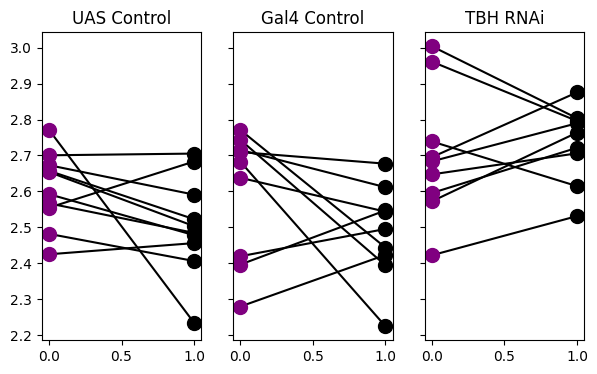

In [81]:
fig,ax = plt.subplots(1,3,sharey=True, figsize=[7,4])

c_df = widths_df_plot.loc[widths_df_plot['rnai']=='control']
ax[0].set_title('UAS Control')

ax[0].plot([0,1], c_df[['dark_width', 'cl_width']].T, color='black', zorder=-1)
ax[0].scatter(np.zeros((c_df.shape[0],)), c_df['dark_width'], color='purple', alpha=1, s=100)
ax[0].scatter(np.ones((c_df.shape[0],)), c_df['cl_width'], color='black', alpha=1, s=100)

gal4_df = widths_df_plot.loc[widths_df_plot['rnai']=='gal4_control']
ax[1].set_title('Gal4 Control')
ax[1].plot([0,1], gal4_df[['dark_width', 'cl_width']].T, color='black', zorder=-1)
ax[1].scatter(np.zeros((gal4_df.shape[0],)), gal4_df['dark_width'], color='purple', alpha=1, s=100)
ax[1].scatter(np.ones((gal4_df.shape[0],)), gal4_df['cl_width'], color='black', alpha=1, s=100)

tbh_df = widths_df_plot.loc[widths_df_plot['rnai']=='rnai_67968']
ax[2].set_title('TBH RNAi')
ax[2].plot([0,1], tbh_df[['dark_width', 'cl_width']].T, color='black', zorder=-1)
ax[2].scatter(np.zeros((tbh_df.shape[0],)), tbh_df['dark_width'], color='purple', alpha=1, s=100)
ax[2].scatter(np.ones((tbh_df.shape[0],)), tbh_df['cl_width'], color='black', alpha=1, s=100)



In [82]:
for condition in ['control', 'gal4_control', 'rnai_67968']:
    print(condition)
    cond_df = widths_df_plot.loc[widths_df_plot['rnai']==condition]
    t,p = sp.stats.wilcoxon(cond_df['dark_width'], cond_df['cl_width'])
    print(t,p)

control
10.0 0.083984375
gal4_control
13.0 0.30078125
rnai_67968
19.0 0.734375


In [ ]:
fig, ax = plt.subplots(figsize=[5,5])
# fly_ids = sess_df['fly_id'].unique()
dark = []
cl = []

for r, fly in enumerate(fly_ids[:]):
    try:
        dark_sess = sess_df.loc[(sess_df['fly_id']==fly) & (sess_df['closed_loop']==0)].iloc[0]
        cl_sess = sess_df.loc[(sess_df['fly_id']==fly) & (sess_df['closed_loop']==2)].iloc[0]

        ts = nmp.session.GetTS(load_row(dark_sess), t_sigma=.1, h_sigma=.1,zscore=False)
        # print(ts.dff.shape)
        # dff_max_aligned_dark = nmp.ring_analysis.shift_by_max(ts.dff[np.newaxis, :, :], sortby_index=0)
        dff_max_aligned_dark, _, _, rho_dark, harmonic_ratio_dark = nmp.ring_analysis.phase_null(ts.dff.T)
        dff_max_aligned_dark = dff_max_aligned_dark.T

        ts = nmp.session.GetTS(load_row(cl_sess), t_sigma=.1, h_sigma=.1, zscore=False)
        dff_max_aligned_cl, _, _, rho_cl, harmonic_ratio_cl = nmp.ring_analysis.phase_null(ts.dff.T)
        dff_max_aligned_cl = dff_max_aligned_cl.T

        
        dark.append(dff_max_aligned_dark[:, rho_dark>.05].mean(axis=1))
        cl.append(dff_max_aligned_cl[:, rho_cl>.05].mean(axis=1))
        
    except:
        print(f'Error loading {fly}')

# dark = np.stack(dark)
# cl = np.stack(cl)
# print(dark.shape, cl.shape)

# mu, sem = np.nanmean(dark, axis=0), sp.stats.sem(dark, axis=0, nan_policy='omit')
# ax.plot(mu, color='purple', linewidth=5, label='dark')
# ax.fill_between(np.arange(mu.size), mu-sem, mu+sem, color='purple', alpha=.3)

# mu, sem = np.nanmean(cl, axis=0), sp.stats.sem(cl, axis=0, nan_policy='omit')
# ax.plot(mu, color='black', linewidth=5, label='closed loop')
# ax.fill_between(np.arange(mu.size), mu-sem, mu+sem, color='black', alpha=.3)


# fig, ax = plt.subplots(figsize=[5,5])
# dark_norm = (dark - np.nanmin(dark, axis=1, keepdims=True)) / (np.nanmax(dark, axis=1, keepdims=True) - np.nanmin(dark, axis=1, keepdims=True))
# cl_norm = (cl - np.nanmin(cl, axis=1, keepdims=True)) / (np.nanmax(cl, axis=1, keepdims=True) - np.nanmin(cl, axis=1, keepdims=True))
# mu, sem = np.nanmean(dark_norm, axis=0), sp.stats.sem(dark_norm, axis=0, nan_policy='omit')
# ax.plot(mu, color='purple', linewidth=5, label='dark')
# ax.fill_between(np.arange(mu.size), mu-sem, mu+sem, color='purple', alpha=.3)   
# mu, sem = np.nanmean(cl_norm, axis=0), sp.stats.sem(cl_norm, axis=0, nan_policy='omit')
# ax.plot(mu, color='black', linewidth=5, label='closed loop')
# ax.fill_between(np.arange(mu.size), mu-sem, mu+sem, color='black', alpha=.3)

/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/two_photon/tbh_rnai.py:395: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(figsize=[8, 4])


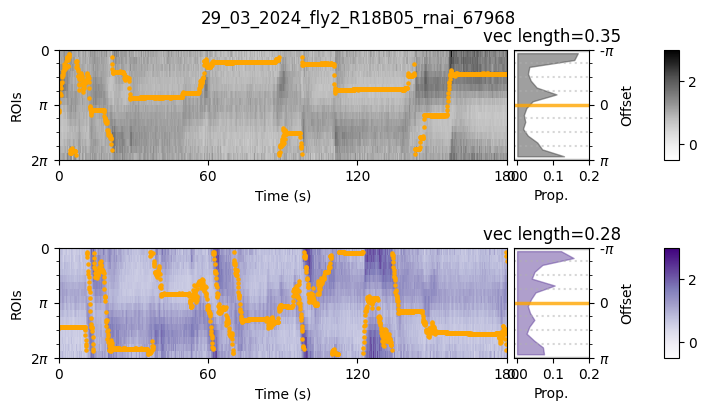

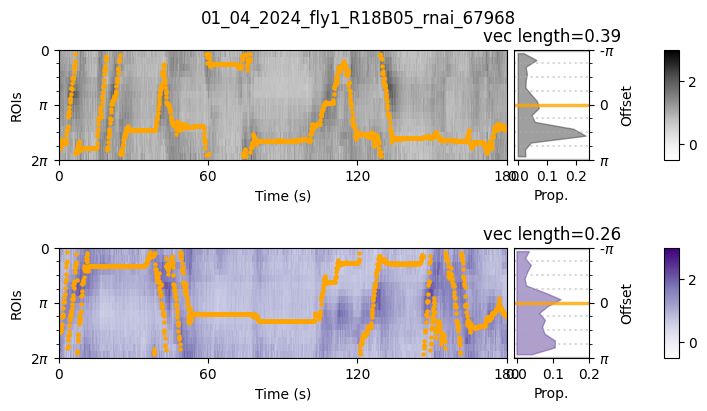

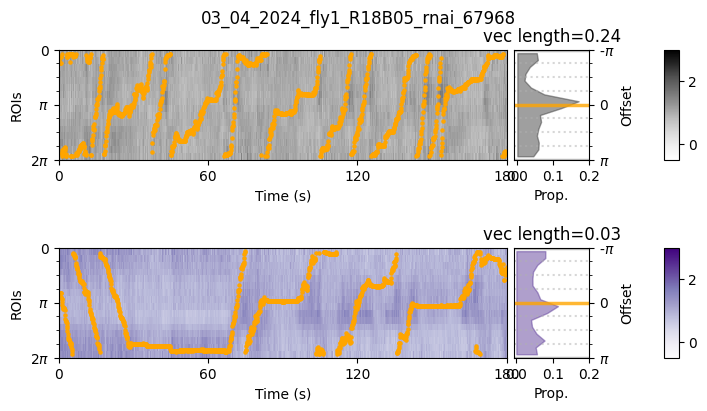

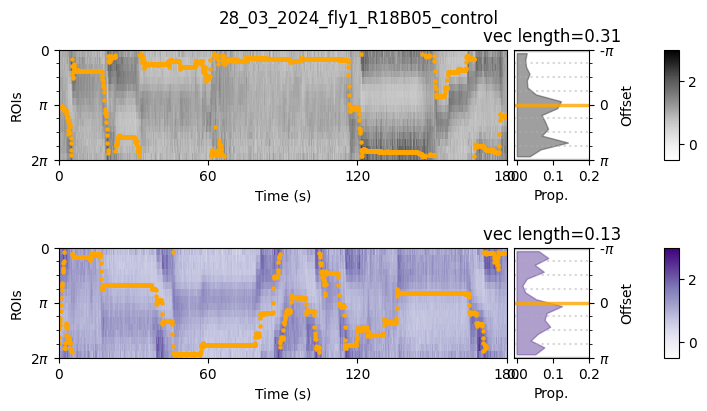

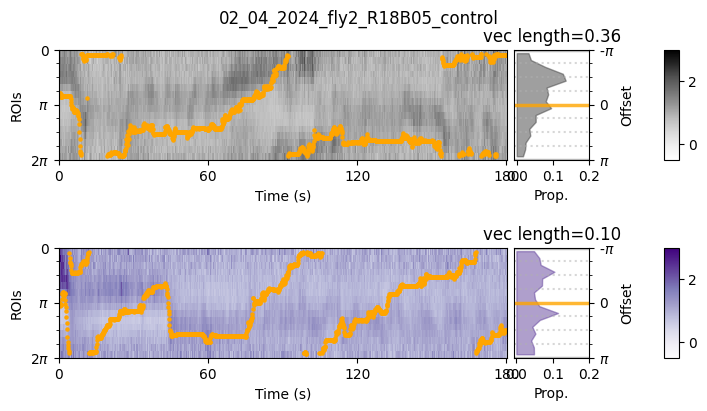

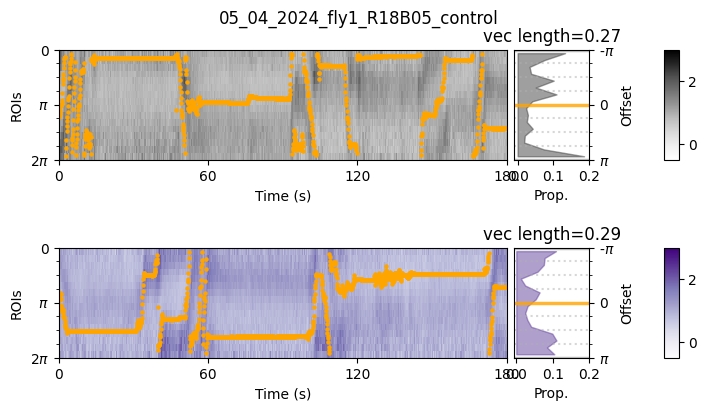

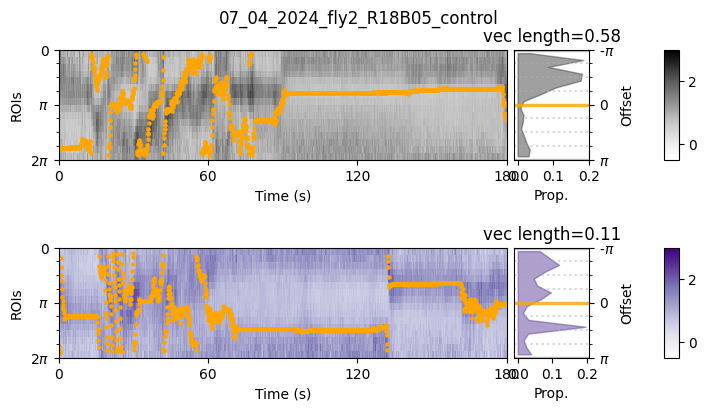

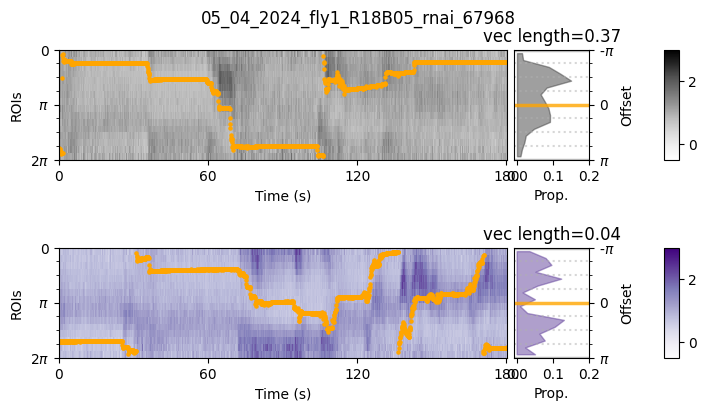

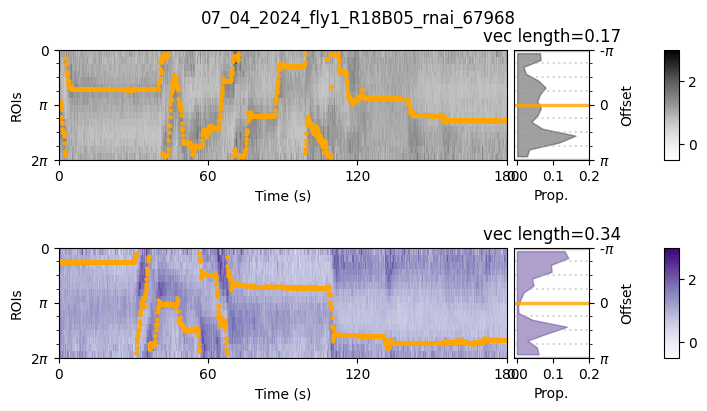

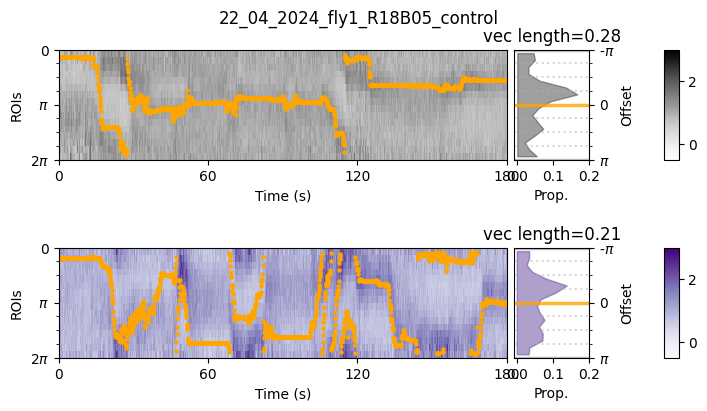

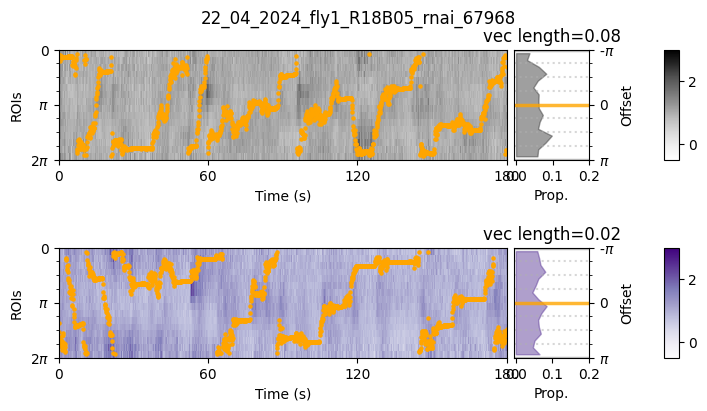

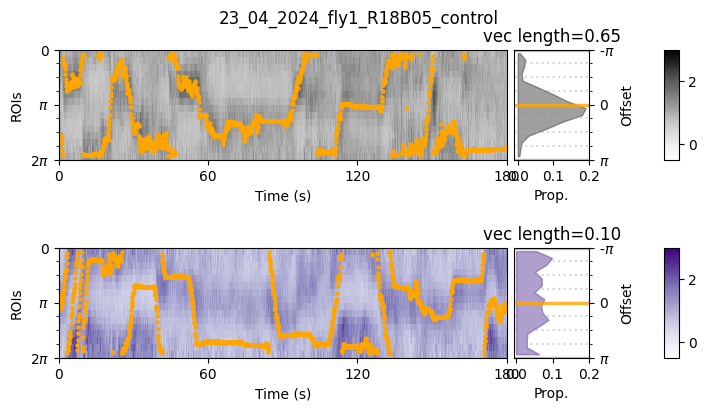

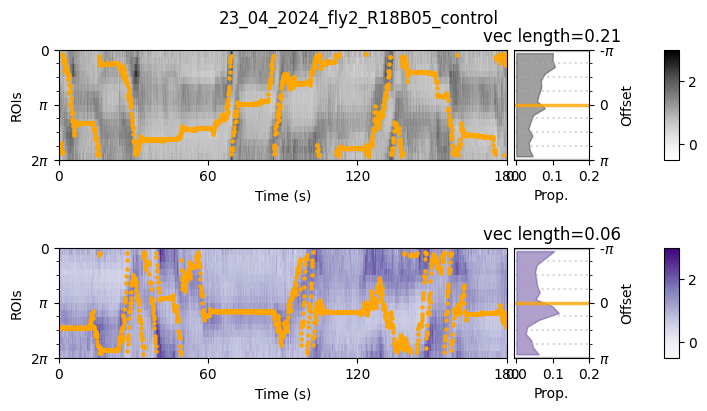

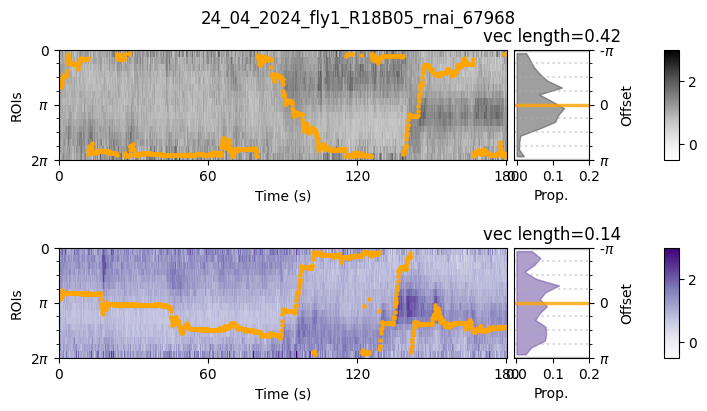

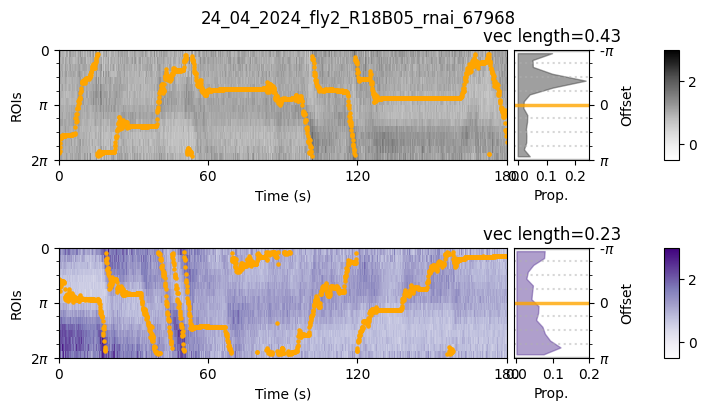

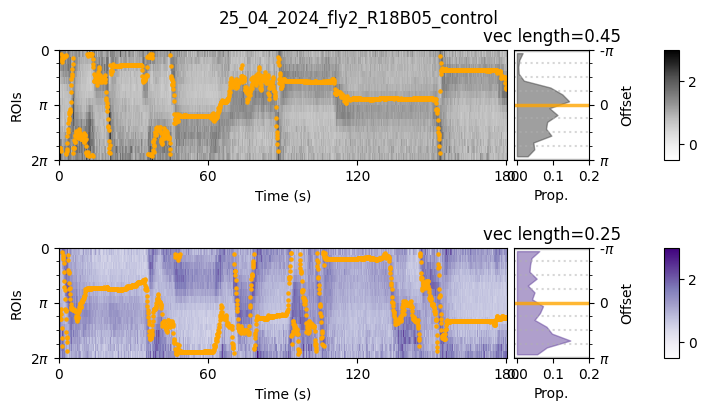

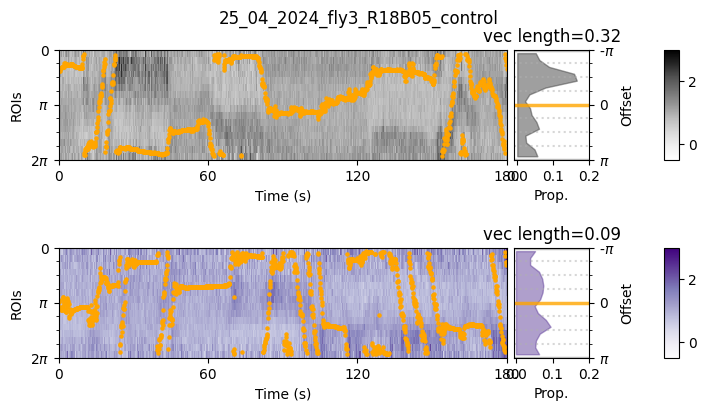

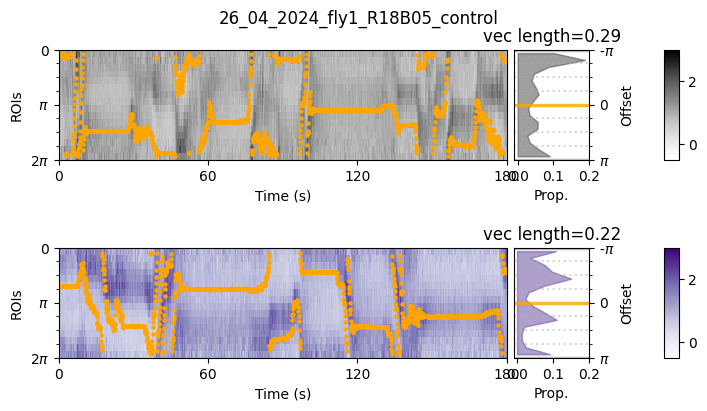

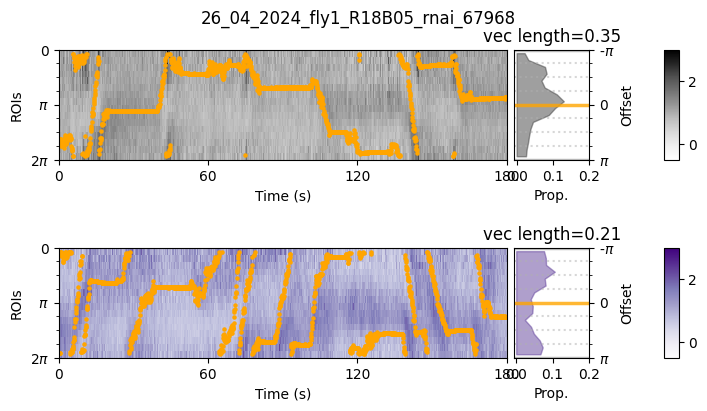

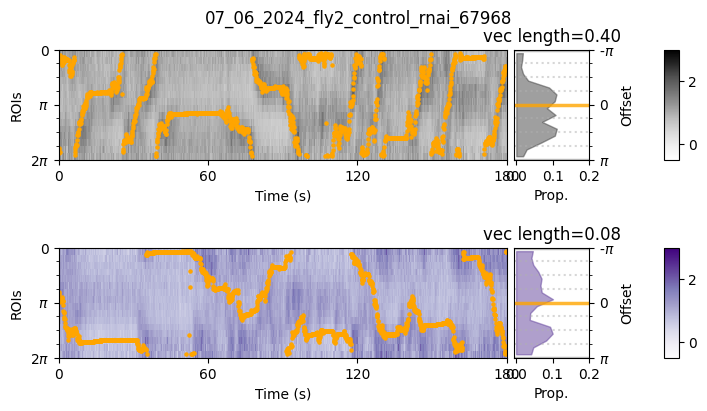

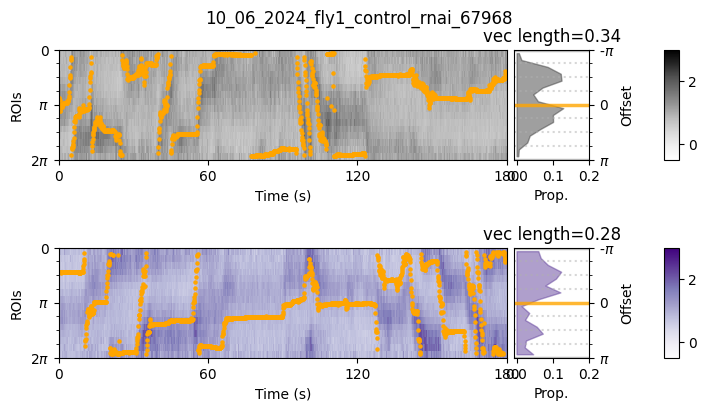

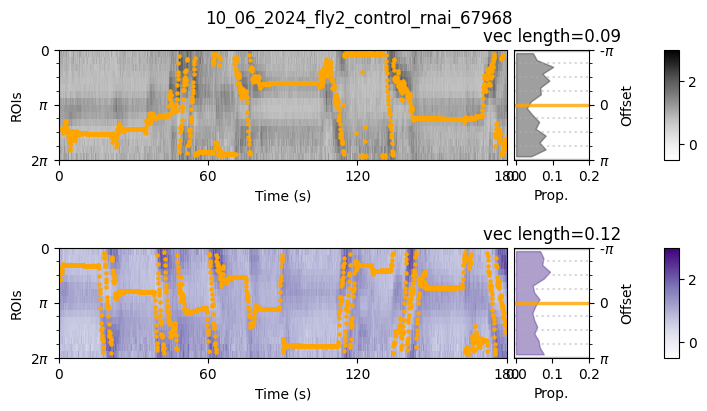

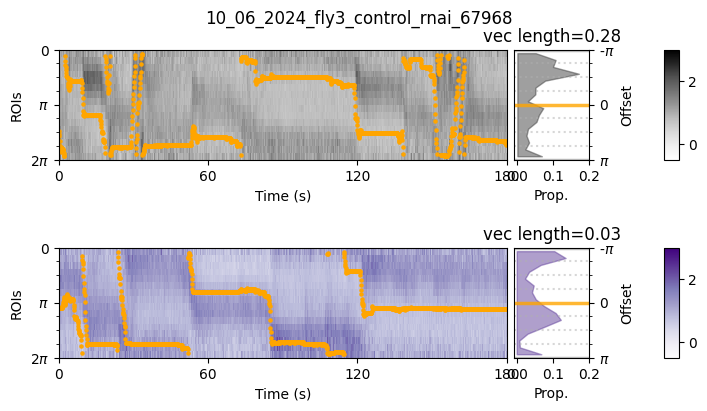

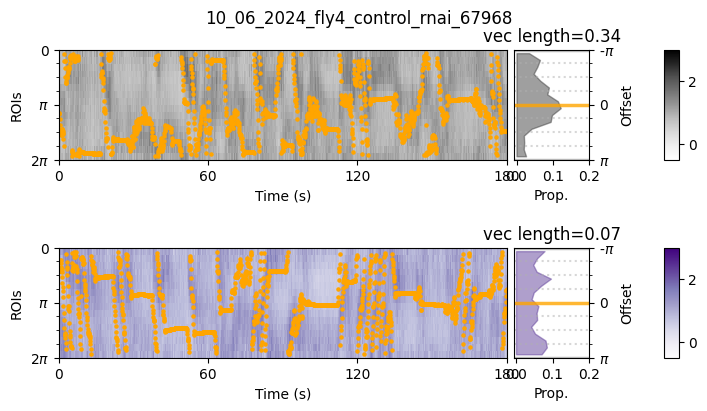

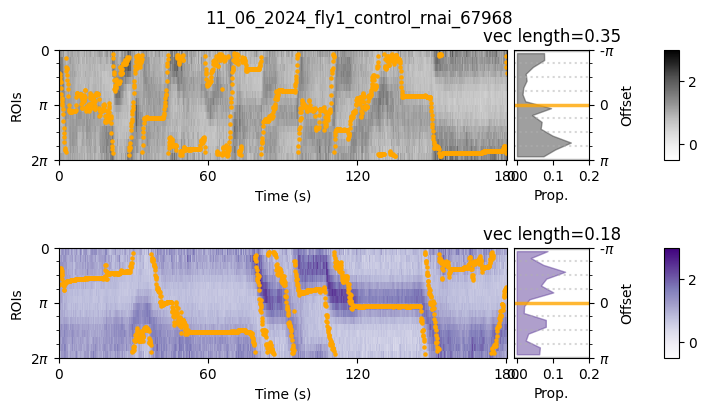

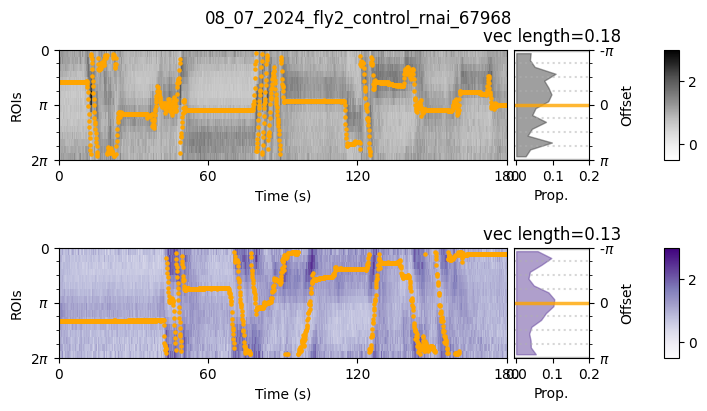

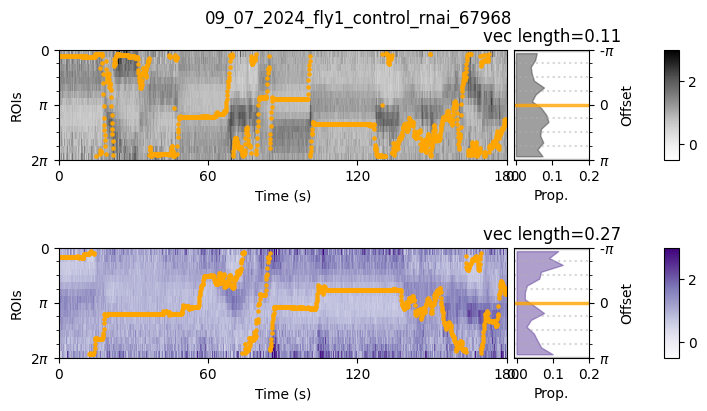

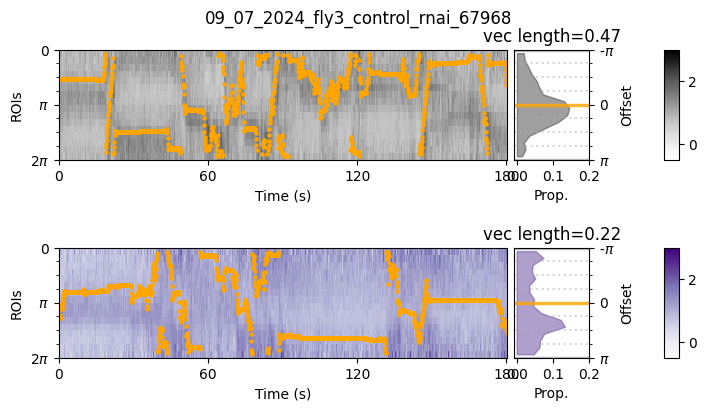

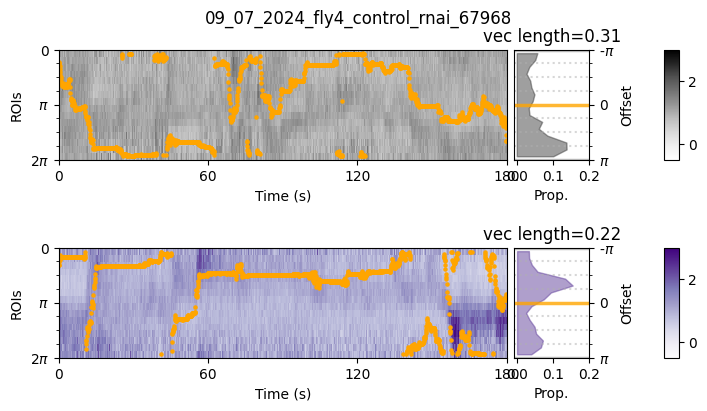

In [22]:
# plot each fly
session_folder = figfolder / "sessions"
session_folder.mkdir(parents=True, exist_ok=True)

flies = sess_df['fly_id'].unique()
for fly in flies:
    
    cl = sess_df.loc[(sess_df['fly_id']==fly) * (sess_df['closed_loop']>1)]
    dark = sess_df.loc[(sess_df['fly_id']==fly) * (sess_df['dark']==1)]
    
    if cl.shape[0]>0 and dark.shape[0]>0:
        
        ts_dict = {'fly': fly,
                   'closed_loop': nmp.session.GetTS(load_row(cl.iloc[0]),zscore=False),
                   'dark': nmp.session.GetTS(load_row(dark.iloc[0]),zscore=False),
        }
        
        fig_heatmaps, ax_heatmas = nmp.tbh_rnai.plot_sess_heatmaps_w_hist(ts_dict, twindow=[0,180.1])
        
    
    
    fly_folder = session_folder / fly
    fly_folder.mkdir(parents=True, exist_ok=True)
    
    fig_heatmaps.savefig(fly_folder / "heatmaps.pdf")
    